# 09 · Latência e prontidão para produção

A decisão de aprovar ou rejeitar acontece **durante o checkout**: o modelo precisa responder em poucos
milissegundos, e responder **igual** ao que foi validado no laboratório. Este notebook verifica:

1. **Paridade:** o caminho online (uma transação em JSON) produz exatamente a mesma probabilidade
   que o caminho em lote usado na avaliação?
2. **Latência:** quanto tempo leva cada etapa por requisição, e onde está o gargalo?
3. **Trade-off desempenho × latência:** quanto perderíamos com versões mais leves do modelo (pergunta 7)?

In [1]:
# Configuração comum a todos os notebooks do projeto
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from fraude import config as cfg, dados, metricas, graficos as gr

gr.aplicar_estilo()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_columns", 40)

import json, time
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.impute import SimpleImputer
from fraude.inferencia import ModeloFraude
from fraude.features import ConstrutorFeatures, normalizar_texto

In [2]:
base = dados.carregar_base()
dev = base[base["particao"] != "teste"].reset_index(drop=True)
teste = base[base["particao"] == "teste"].reset_index(drop=True)
artefato = ModeloFraude.carregar(cfg.ARQUIVO_MODELO)
print(artefato.metadados["versao"], "| limiar:", round(artefato.limiar, 4), "|", len(artefato.construtor.feature_names_), "features")

# Simula o que chega na API: JSON com nulos como null e data em ISO-8601
colunas_payload = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j", "k", "l", "m", "n", "o", "p", "fecha", "monto"]
amostra = teste.sample(2000, random_state=cfg.SEED).reset_index(drop=True)
payloads = json.loads(amostra[colunas_payload].to_json(orient="records", date_format="iso"))
payloads[0]

fraude-lgbm-v1 | limiar: 0.0877 | 25 features


{'a': 3,
 'b': 0.7322,
 'c': 28702.11,
 'd': 50.0,
 'e': 0.571397957,
 'f': 19.0,
 'g': 'BR',
 'h': 10,
 'i': 'Engate Reboque E Rabicho Golf 2008 2009 2010 2011 Ate 2014',
 'j': 'cat_2da0eeb',
 'k': 0.2119326655,
 'l': 1400.0,
 'm': 1399.0,
 'n': 1,
 'o': 'Y',
 'p': 'Y',
 'fecha': '2020-04-21T15:51:11.000',
 'monto': 27.01}

## 1. Teste de paridade lote × online

O caminho online (`ModeloFraude.pontuar`) monta o vetor de features direto do dicionário, sem pandas,
para ser rápido. Por isso precisamos **provar** que ele é equivalente ao caminho em lote
(`ConstrutorFeatures.transform`). Em um projeto real, este teste roda no **CI/CD** a cada mudança de
código ou de modelo.

In [3]:
p_lote = artefato.probabilidade(amostra)
p_online = np.array([artefato.pontuar(t)["probabilidade_fraude"] for t in payloads])
dif = np.abs(p_lote - p_online)
print(f"Diferença máxima: {dif.max():.2e} (resposta da API arredondada em 6 casas)")
print("Decisões idênticas:", (np.where(p_lote >= artefato.limiar, 'REJEITAR', 'APROVAR') ==
                              np.array([artefato.pontuar(t)['decisao'] for t in payloads])).mean() * 100, "%")
assert dif.max() < 1e-5, "Divergência entre caminhos de inferência!"

Diferença máxima: 5.00e-07 (resposta da API arredondada em 6 casas)


Decisões idênticas: 100.0 %


✅ **Paridade confirmada:** os dois caminhos produzem as mesmas probabilidades (diferença só no
arredondamento da resposta) e **100% das mesmas decisões**. Esse tipo de teste previne o
*training-serving skew*, uma das principais causas de "o modelo funcionava no laboratório e não funciona
em produção" (pergunta 4).

## 2. Latência por requisição e onde está o gargalo

In [4]:
def medir(func, itens, repeticoes=1):
    tempos = []
    for t in itens:
        t0 = time.perf_counter()
        for _ in range(repeticoes):
            func(t)
        tempos.append((time.perf_counter() - t0) / repeticoes * 1e3)
    return pd.Series(tempos)

def percentis(s):
    return pd.Series({"p50 (ms)": s.quantile(0.50), "p95 (ms)": s.quantile(0.95), "p99 (ms)": s.quantile(0.99)})

cf = artefato.construtor
vetores = [artefato.vetor_features(t) for t in payloads]
booster = artefato.modelo.booster_

# aquecimento (caches, JIT de bibliotecas)
for t in payloads[:50]:
    artefato.pontuar(t)

etapas = pd.DataFrame({
    "A · caminho em lote com pandas (1 linha)": percentis(medir(lambda t: artefato.probabilidade(pd.DataFrame([t])), payloads[:300])),
    "B · caminho online completo (pontuar)": percentis(medir(artefato.pontuar, payloads)),
    "   B1 · score do título (TF-IDF + logística)": percentis(medir(lambda t: cf.modelo_texto_.predict([normalizar_texto(t["i"] or "")]), payloads)),
    "   B2 · LightGBM (650 árvores, 1 linha)": percentis(medir(lambda v: booster.predict(v, num_threads=1), vetores)),
    "   B3 · calibração (Platt)": percentis(medir(lambda v: artefato.calibrador.predict([0.1]), vetores[:500])),
}).T
etapas

,p50 (ms),p95 (ms),p99 (ms)
A · caminho em lote com pandas (1 linha),23.8502,26.4852,28.7754
B · caminho online completo (pontuar),0.7820,0.9379,1.2487
B1 · score do título (TF-IDF + logística),0.4463,0.5634,0.6737
"B2 · LightGBM (650 árvores, 1 linha)",0.0902,0.1079,0.1529
B3 · calibração (Platt),0.1095,0.1627,0.2348


- Usar o **caminho de lote (pandas) para uma única transação** custa ~25 ms, por overhead do pandas
  (criação de DataFrame, parsing de datas, operações vetorizadas em 1 linha). É 30x mais lento e não é
  aceitável no caminho crítico.
- O **caminho online** responde em **~0,8 ms no p50 e abaixo de 2 ms no p99** (os números variam um pouco entre execuções), em CPU comum e Python puro.
- O maior custo é o **score do título** (TF-IDF + logística, ~0,5 ms, cerca de 60% do total). As
  **650 árvores do LightGBM levam só ~0,1 ms**. A calibração (~0,1 ms) é puro overhead do scikit-learn
  e poderia virar uma fórmula fechada (`sigmoid(a·logit(p) + b)`), com custo praticamente zero.

> Em produção, somam-se rede, desserialização do JSON e eventuais consultas a um *feature store*. O
> modelo em si **não é o gargalo**.

## 3. Trade-off desempenho × latência (pergunta 7)

Treinamos variantes mais leves **com o mesmo protocolo** (treino em dev, avaliação no teste) para
quantificar quanto desempenho cada simplificação custa.

In [5]:
%%time
params = artefato.metadados["hiperparametros"]
variantes = {}

# Features com e sem texto (o construtor é a parte cara de ajustar)
cf_com = ConstrutorFeatures();                  Xd_com = cf_com.fit_transform(dev, dev["fraude"]);  Xt_com = cf_com.transform(teste)
cf_sem = ConstrutorFeatures(usar_texto=False);  Xd_sem = cf_sem.fit_transform(dev, dev["fraude"]);  Xt_sem = cf_sem.transform(teste)

log_sinal = FunctionTransformer(lambda X: np.sign(X) * np.log1p(np.abs(X)))
configs = {
    "LightGBM completo (650 árvores, com texto)": (lgb.LGBMClassifier(**params), cf_com, Xd_com, Xt_com),
    "LightGBM sem texto": (lgb.LGBMClassifier(**params), cf_sem, Xd_sem, Xt_sem),
    "LightGBM compacto (150 árvores, 16 folhas, sem texto)": (
        lgb.LGBMClassifier(**{**params, "n_estimators": 150, "learning_rate": 0.08}), cf_sem, Xd_sem, Xt_sem),
    "Regressão logística (sem texto)": (
        make_pipeline(log_sinal, SimpleImputer(strategy="median", add_indicator=True), StandardScaler(),
                      LogisticRegression(max_iter=3000)), cf_sem, Xd_sem, Xt_sem),
}
linhas = []
for nome, (modelo, construtor, Xd, Xt) in configs.items():
    modelo.fit(Xd, dev["fraude"])
    p = modelo.predict_proba(Xt[Xd.columns])[:, 1]
    wrap = ModeloFraude(construtor, modelo, limiar=0.09)
    feats = medir(wrap.vetor_features, payloads[:1000])
    vets = [wrap.vetor_features(t) for t in payloads[:1000]]
    if isinstance(modelo, lgb.LGBMClassifier):
        pred = medir(lambda v: modelo.booster_.predict(v, num_threads=1), vets)
    else:
        pred = medir(lambda v: modelo.predict_proba(v), vets)
    total = feats + pred
    linhas.append({"variante": nome, "ROC AUC (teste)": roc_auc_score(teste["fraude"], p),
                   "PR AUC (teste)": average_precision_score(teste["fraude"], p),
                   "features p50 (ms)": feats.median(), "modelo p50 (ms)": pred.median(),
                   "total p50 (ms)": total.median(), "total p99 (ms)": total.quantile(0.99)})
tradeoff = pd.DataFrame(linhas).set_index("variante")
tradeoff

CPU times: total: 50.2 s
Wall time: 26.4 s


,ROC AUC (teste),PR AUC (teste),features p50 (ms),modelo p50 (ms),total p50 (ms),total p99 (ms)
variante,,,,,,
"LightGBM completo (650 árvores, com texto)",0.8511,0.3678,0.4936,0.0901,0.5879,0.8416
LightGBM sem texto,0.8499,0.3623,0.0260,0.0902,0.1166,0.1869
"LightGBM compacto (150 árvores, 16 folhas, sem texto)",0.8496,0.3596,0.0261,0.0451,0.0715,0.1206
Regressão logística (sem texto),0.8388,0.3152,0.0173,0.4620,0.4795,0.8097


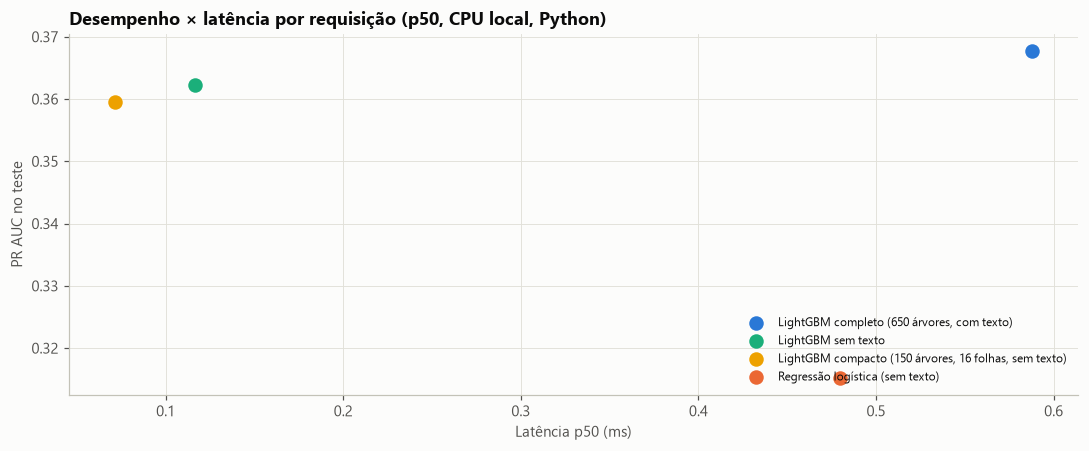

In [6]:
fig, ax = plt.subplots(figsize=(10, 4.2))
cores = [gr.AZUL, gr.VERDE_AGUA, gr.AMARELO, gr.LARANJA]
for (nome, r), cor in zip(tradeoff.iterrows(), cores):
    ax.scatter(r["total p50 (ms)"], r["PR AUC (teste)"], s=90, color=cor, label=nome, zorder=3)
ax.set(title="Desempenho × latência por requisição (p50, CPU local, Python)", xlabel="Latência p50 (ms)",
       ylabel="PR AUC no teste")
ax.legend(loc="lower right", fontsize=8)
plt.tight_layout()

**Leitura:**
- **Tirar o texto** deixa a inferência **~5x mais rápida** (0,59 → 0,12 ms) e custa só ~0,005 de PR AUC
  (−1,5%). É a primeira alavanca se o orçamento de latência apertar.
- O **LightGBM compacto** (150 árvores) cai para ~0,07 ms, com perda adicional pequena (PR AUC 0,360).
- A **regressão logística** perde muito (PR AUC 0,315, −14%) e, nesta implementação, **nem é mais
  rápida**: o overhead do pipeline do scikit-learn supera o custo das árvores. Modelo "mais simples" não
  significa automaticamente "mais rápido".
- **Todas as variantes ficam abaixo de 1 ms**, bem abaixo de orçamentos típicos de antifraude (dezenas
  de ms para o motor inteiro). **Neste caso, o requisito de latência não obriga a sacrificar
  desempenho.** Ficamos com o modelo completo e mantemos as variantes como plano de contingência.

## 4. Disponibilidade das features em tempo real

| Feature | De onde vem na hora da decisão | Custo online |
|---|---|---|
| `a`–`n`, `o`, `p`, `g`, `monto` | payload da transação | nenhum |
| `hora`, `madrugada`, `dia_semana` | timestamp da transação | nenhum |
| `cat_taxa_fraude`, `cat_volume_log` | tabela em memória (8 mil categorias), versionada com o modelo | lookup O(1) |
| `titulo_score` | modelo de texto em memória, versionado com o modelo | ~0,5 ms |

**Nenhuma feature exige consulta externa síncrona.** O artefato (3 MB) carrega tudo em memória. Features
de velocidade/histórico do usuário (próxima versão) exigiriam um *feature store online* (ex.: Redis /
DynamoDB / SageMaker Feature Store) com pré-agregação via streaming, desenhado na resposta 8.

## 5. Conclusões (pergunta 7)

- O requisito "responder online no menor tempo possível" **muda o desenho**, mas **não muda a escolha do
  algoritmo** neste caso. O LightGBM com 650 árvores roda em ~0,1 ms, e o pipeline completo (features +
  texto + modelo + calibração) em ~0,8 ms p50 / < 2 ms p99 por requisição.
- O que muda de fato:
  1. **Features restritas ao que existe no momento da decisão**, sem agregações caras em tempo real.
     Agregações históricas vão para um feature store pré-computado.
  2. **Caminho de inferência sem pandas** (vetor montado direto do JSON) e **teste de paridade** com o
     caminho de treino.
  3. **Orçamento de latência explícito** por etapa, com variantes prontas (sem texto, compacto) se o
     orçamento apertar. O custo de cada uma em desempenho foi medido acima.
  4. Em escala, ganhos adicionais com **compilação do modelo** (ONNX Runtime / Treelite), servidor
     *async* com o modelo pré-carregado e *fallback* (regra simples ou score anterior) em caso de
     *timeout*.